# Parte 2. Validación de las pruebas de hipótesis mediante permutación

**Resultados de la S1 que se validan (sección 4 del informe):**

| Prueba S1 | Estadístico | Valor p S1 | Decisión S1 |
| --- | --- | --- | --- |
| 1. Presión sistólica según CHD (Welch) | t = 12,01; gl = 783,8; diferencia = 13,28 mmHg | < 0,001 | Se rechaza H₀ |
| 2. Tabaquismo y CHD (χ² con Yates) | χ² = 1,50; gl = 1; tasas 15,9 % vs 14,5 % | 0,221 | No se rechaza H₀ |

**Idea del test de permutación.** Si H₀ es cierta (no hay relación entre la etiqueta de grupo y la variable
respuesta), las etiquetas son *intercambiables*: cualquier reasignación de ellas es igual de probable que la
observada. Se reasignan las etiquetas al azar B = 10.000 veces con `rng.permutation`, se recalcula el
estadístico en cada reasignación y se obtiene su distribución nula sin suponer normalidad ni usar
aproximaciones asintóticas. El valor p es la proporción de estadísticos permutados al menos tan extremos
como el observado, con la corrección (k + 1)/(B + 1) de `p_valor_permutacion` (el p mínimo es 1/10.001).
Como el p de permutación es a su vez una estimación Monte Carlo, se informa su error estándar
√(p(1 − p)/B) y se verifica su convergencia.

## Configuración

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.contingency_tables import StratifiedTable

from utils_s2 import (
    SEED, B, ALPHA, RESULTADOS_S1, NOMBRES, NUM, COLORES,
    cargar_datos, configurar_graficos, guardar_figura, guardar_tabla,
    ic_bootstrap, p_valor_permutacion, jackknife, media_acumulada,
)

configurar_graficos()
rng = np.random.default_rng(SEED)
df = cargar_datos()
print(f"Observaciones: {df.shape[0]} | Variables: {df.shape[1]} | B = {B:,} | semilla = {SEED}")

Observaciones: 4240 | Variables: 16 | B = 10,000 | semilla = 42


In [2]:
# Los datos deben reproducir las cifras de la S1
assert round(df["age"].mean(), 2) == RESULTADOS_S1["ic"]["edad_media"]["estimacion"]
assert round(df["sysBP"].mean(), 2) == RESULTADOS_S1["ic"]["sysbp_media"]["estimacion"]
assert round(df["totChol"].mean(), 2) == RESULTADOS_S1["ic"]["colesterol_media"]["estimacion"]
assert round(df["TenYearCHD"].mean() * 100, 2) == RESULTADOS_S1["ic"]["prop_chd_%"]["estimacion"]
print("OK: los datos coinciden con la Sumativa 1")

OK: los datos coinciden con la Sumativa 1


### Funciones de apoyo

Para no guardar una matriz de 10.000 × 4.240 en memoria, las permutaciones se generan por lotes: cada fila
del lote es una permutación independiente de las etiquetas (`rng.permuted` aplica `rng.permutation` fila a
fila). Con una matriz de etiquetas 0/1, las sumas por grupo se obtienen con un producto matricial, lo que
permite calcular a la vez la diferencia de medias y el t de Welch de cada permutación.

In [3]:
def permutaciones_por_lotes(etiquetas, n_perm=B, rng=rng, lote=1_000):
    # Genera lotes de etiquetas permutadas (cada fila es una permutación independiente)
    etiquetas = np.asarray(etiquetas)
    hechas = 0
    while hechas < n_perm:
        m = min(lote, n_perm - hechas)
        yield rng.permuted(np.tile(etiquetas, (m, 1)), axis=1)
        hechas += m


def resumen_grupos(L, x):
    # Medias y varianzas de los grupos etiqueta = 1 y etiqueta = 0 para cada fila de L
    L = L.astype(float)
    n1 = L.sum(axis=-1)
    n0 = L.shape[-1] - n1
    s1, s0 = L @ x, (1 - L) @ x
    q1, q0 = L @ x**2, (1 - L) @ x**2
    m1, m0 = s1 / n1, s0 / n0
    v1 = (q1 - n1 * m1**2) / (n1 - 1)
    v0 = (q0 - n0 * m0**2) / (n0 - 1)
    return m1, m0, v1, v0, n1, n0


def dif_y_welch(L, x):
    # Diferencia de medias (grupo 1 - grupo 0) y estadístico t de Welch
    m1, m0, v1, v0, n1, n0 = resumen_grupos(L, x)
    dif = m1 - m0
    return dif, dif / np.sqrt(v1 / n1 + v0 / n0)


def ee_mc(p, n=B):
    # Error estándar Monte Carlo de un valor p estimado con n permutaciones
    return np.sqrt(p * (1 - p) / n)


def fmt_p(p):
    return "< 0,0001" if p < 1e-4 else f"{p:.4f}".replace(".", ",")

## 2.1 Prueba 1: presión sistólica y CHD

- **H₀:** la presión sistólica tiene la misma distribución en quienes desarrollan y no desarrollan CHD
  (las etiquetas `TenYearCHD` son intercambiables respecto de `sysBP`).
- **H₁:** la presión sistólica difiere entre ambos grupos (bilateral, α = 0,05).

Se usan dos estadísticos sobre las mismas 10.000 permutaciones: la **diferencia de medias**
(con CHD − sin CHD), que es la magnitud reportada en la S1, y el **t de Welch**, que es el estadístico de la
prueba original. El t studentizado es preferible como estadístico de permutación cuando las varianzas de
los grupos difieren (Levene rechazó la homogeneidad en la S1), porque mantiene el test válido aunque la
H₀ de intercambiabilidad completa no se cumpla y solo se quiera contrastar la igualdad de medias.

In [4]:
pas = df["sysBP"].to_numpy(float)
chd = df["TenYearCHD"].to_numpy(int)

dif_obs, t_obs = dif_y_welch(chd[None, :], pas)
dif_obs, t_obs = dif_obs.item(), t_obs.item()
welch = stats.ttest_ind(pas[chd == 1], pas[chd == 0], equal_var=False)
assert round(dif_obs, 2) == RESULTADOS_S1["pruebas"]["sysbp_chd"]["dif"]
assert round(welch.statistic, 2) == RESULTADOS_S1["pruebas"]["sysbp_chd"]["estadistico"]

nula_dif_pas, nula_t_pas = [], []
for L in permutaciones_por_lotes(chd):
    d, t = dif_y_welch(L, pas)
    nula_dif_pas.append(d)
    nula_t_pas.append(t)
nula_dif_pas = np.concatenate(nula_dif_pas)
nula_t_pas = np.concatenate(nula_t_pas)

p_perm_dif_pas = p_valor_permutacion(dif_obs, nula_dif_pas)
p_perm_t_pas = p_valor_permutacion(t_obs, nula_t_pas)
k_pas = int(np.sum(np.abs(nula_dif_pas) >= abs(dif_obs)))
z_pas = dif_obs / nula_dif_pas.std(ddof=1)

print(f"Diferencia observada: {dif_obs:.2f} mmHg | t de Welch: {t_obs:.2f} (gl = {welch.df:.1f})")
print(f"Permutaciones con |dif*| >= |dif obs|: {k_pas} de {B:,}")
print(f"p de permutación (diferencia): {p_perm_dif_pas:.6f} | p de permutación (t de Welch): {p_perm_t_pas:.6f}")
print(f"Máximo |dif*| bajo H0: {np.abs(nula_dif_pas).max():.2f} mmHg | DE de la nula: {nula_dif_pas.std(ddof=1):.3f}")
print(f"El observado está a {z_pas:.1f} DE del centro de la distribución nula")
print(f"p paramétrico de Welch: {welch.pvalue:.2e}")

Diferencia observada: 13.28 mmHg | t de Welch: 12.01 (gl = 783.8)
Permutaciones con |dif*| >= |dif obs|: 0 de 10,000
p de permutación (diferencia): 0.000100 | p de permutación (t de Welch): 0.000100
Máximo |dif*| bajo H0: 3.43 mmHg | DE de la nula: 0.952
El observado está a 14.0 DE del centro de la distribución nula
p paramétrico de Welch: 1.25e-30


**Validación con SciPy.** Se repite el test con
`scipy.stats.permutation_test` (otra semilla y otra implementación) para comprobar que la distribución nula
manual es correcta: ambas deben tener prácticamente la misma dispersión y el mismo valor p.

In [5]:
def dif_medias(x, y, axis=-1):
    return np.mean(x, axis=axis) - np.mean(y, axis=axis)


res_scipy_pas = stats.permutation_test(
    (pas[chd == 1], pas[chd == 0]), dif_medias, permutation_type="independent",
    n_resamples=B, alternative="two-sided", vectorized=True, batch=500,
    random_state=np.random.default_rng(SEED + 1),
)
print(f"SciPy: dif = {res_scipy_pas.statistic:.2f} | p = {res_scipy_pas.pvalue:.6f} "
      f"| DE de la nula = {res_scipy_pas.null_distribution.std(ddof=1):.3f}")
print(f"Manual: DE de la nula = {nula_dif_pas.std(ddof=1):.3f}")

SciPy: dif = 13.28 | p = 0.000200 | DE de la nula = 0.948
Manual: DE de la nula = 0.952


## 2.2 Prueba 2: tabaquismo y CHD

- **H₀:** fumar (`currentSmoker`) y desarrollar CHD son independientes.
- **H₁:** existe asociación (bilateral, α = 0,05).

Estadístico principal: **diferencia de tasas de CHD** (fumadores − no fumadores). Se permuta la etiqueta
`currentSmoker` manteniendo fijos los márgenes de la tabla 2×2. Con márgenes fijos, el χ² sin corrección es
una función creciente de |diferencia de tasas|, de modo que ambos estadísticos producen exactamente el
mismo valor p de permutación; igualmente se calcula el χ² de cada permutación para comparar la
distribución nula empírica con la distribución χ²₁ teórica que usó la S1.

In [6]:
fuma = df["currentSmoker"].to_numpy(int)
y_chd = chd.astype(float)
N = len(y_chd)


def dif_tasas_y_chi2(L, y):
    # Diferencia de tasas (etiqueta 1 - etiqueta 0) y chi-cuadrado sin corrección de la tabla 2x2
    L = L.astype(float)
    n1 = L.sum(axis=-1)
    n0 = L.shape[-1] - n1
    a = L @ y                      # etiqueta 1 con CHD
    c = y.sum() - a                # etiqueta 0 con CHD
    dif = a / n1 - c / n0
    b, d = n1 - a, n0 - c
    c1, c0 = a + c, b + d
    chi2 = len(y) * (a * d - b * c) ** 2 / (n1 * n0 * c1 * c0)
    return dif, chi2


dif_tasas_obs, chi2_obs = (v.item() for v in dif_tasas_y_chi2(fuma[None, :], y_chd))

tabla_fuma = pd.crosstab(df["currentSmoker"], df["TenYearCHD"])
chi_yates = stats.chi2_contingency(tabla_fuma, correction=True)
chi_sin = stats.chi2_contingency(tabla_fuma, correction=False)
fisher = stats.fisher_exact(tabla_fuma)
assert round(chi_yates.statistic, 2) == RESULTADOS_S1["pruebas"]["fumar_chd"]["estadistico"]
assert round(chi_yates.pvalue, 3) == RESULTADOS_S1["pruebas"]["fumar_chd"]["p"]

nula_dif_fuma, nula_chi2_fuma = [], []
for L in permutaciones_por_lotes(fuma):
    d, c2 = dif_tasas_y_chi2(L, y_chd)
    nula_dif_fuma.append(d)
    nula_chi2_fuma.append(c2)
nula_dif_fuma = np.concatenate(nula_dif_fuma)
nula_chi2_fuma = np.concatenate(nula_chi2_fuma)

p_perm_fuma = p_valor_permutacion(dif_tasas_obs, nula_dif_fuma)
p_perm_chi2 = p_valor_permutacion(chi2_obs, nula_chi2_fuma, alternativa="mayor")

print(f"Tasas: fumadores {y_chd[fuma == 1].mean():.2%} | no fumadores {y_chd[fuma == 0].mean():.2%}")
print(f"Diferencia observada: {dif_tasas_obs * 100:.2f} pp | χ² sin corrección: {chi2_obs:.3f}")
print(f"p de permutación (diferencia de tasas): {p_perm_fuma:.4f} ± {ee_mc(p_perm_fuma):.4f} (EE Monte Carlo)")
print(f"p de permutación (χ²): {p_perm_chi2:.4f}")
print(f"p paramétricos: χ² con Yates (S1) = {chi_yates.pvalue:.4f} | χ² sin Yates = {chi_sin.pvalue:.4f} "
      f"| Fisher exacto = {fisher.pvalue:.4f}")

Tasas: fumadores 15.89% | no fumadores 14.50%
Diferencia observada: 1.40 pp | χ² sin corrección: 1.604
p de permutación (diferencia de tasas): 0.2103 ± 0.0041 (EE Monte Carlo)
p de permutación (χ²): 0.2103
p paramétricos: χ² con Yates (S1) = 0.2211 | χ² sin Yates = 0.2054 | Fisher exacto = 0.2147


In [7]:
res_scipy_fuma = stats.permutation_test(
    (y_chd[fuma == 1], y_chd[fuma == 0]), dif_medias, permutation_type="independent",
    n_resamples=B, alternative="two-sided", vectorized=True, batch=500,
    random_state=np.random.default_rng(SEED + 2),
)
print(f"SciPy: dif = {res_scipy_fuma.statistic * 100:.2f} pp | p = {res_scipy_fuma.pvalue:.4f}")
print(f"Diferencia manual vs SciPy: {abs(p_perm_fuma - res_scipy_fuma.pvalue):.4f} "
      f"(≈ {abs(p_perm_fuma - res_scipy_fuma.pvalue) / ee_mc(p_perm_fuma):.1f} EE Monte Carlo)")

SciPy: dif = 1.40 pp | p = 0.2168
Diferencia manual vs SciPy: 0.0065 (≈ 1.6 EE Monte Carlo)


### Convergencia del valor p de permutación

El valor p es la media de los indicadores I(|T*ᵦ| ≥ |T_obs|), por lo que su convergencia se evalúa igual que
la de cualquier estimador Monte Carlo: con la media acumulada y su banda ± 1,96 EE (`media_acumulada`).

In [8]:
indicador_fuma = (np.abs(nula_dif_fuma) >= abs(dif_tasas_obs)).astype(float)
conv_fuma = media_acumulada(indicador_fuma)
hitos = [100, 500, 1_000, 2_500, 5_000, 10_000]
tabla_conv = conv_fuma.set_index("iteracion").loc[hitos].assign(
    IC95_inf=lambda t: t["media"] - 1.96 * t["ee"],
    IC95_sup=lambda t: t["media"] + 1.96 * t["ee"],
    CV_pct=lambda t: 100 * t["ee"] / t["media"],
)
tabla_conv.index.name = "Permutaciones"
guardar_tabla(tabla_conv.round(4), "p2_convergencia_p")

,media,ee,IC95_inf,IC95_sup,CV_pct
Permutaciones,,,,,
100,0.2400,0.0429,0.1559,0.3241,17.8848
500,0.1880,0.0175,0.1537,0.2223,9.3036
1000,0.1840,0.0123,0.1600,0.2080,6.6627
2500,0.2104,0.0082,0.1944,0.2264,3.8752
5000,0.2126,0.0058,0.2013,0.2239,2.7219
10000,0.2102,0.0041,0.2022,0.2182,1.9385


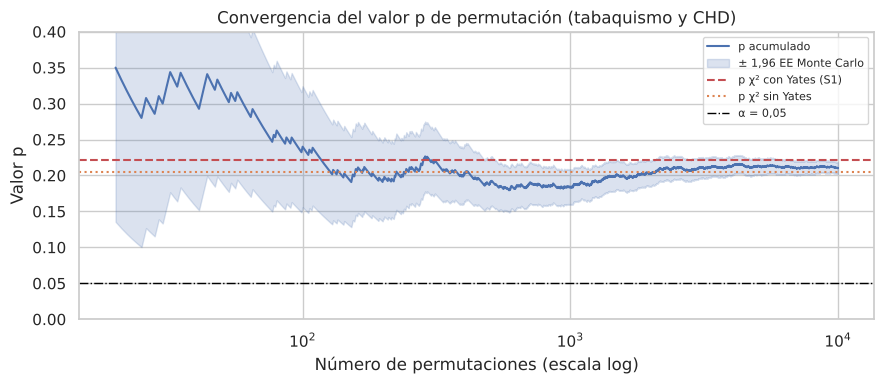

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
conv_plot = conv_fuma[conv_fuma["iteracion"] >= 20]   # las primeras iteraciones solo agregan ruido visual
k = conv_plot["iteracion"]
ax.plot(k, conv_plot["media"], color=COLORES["principal"], lw=1.5, label="p acumulado")
ax.fill_between(k, conv_plot["media"] - 1.96 * conv_plot["ee"], conv_plot["media"] + 1.96 * conv_plot["ee"],
                color=COLORES["principal"], alpha=.2, label="± 1,96 EE Monte Carlo")
ax.axhline(chi_yates.pvalue, color=COLORES["riesgo"], ls="--", lw=1.5, label="p χ² con Yates (S1)")
ax.axhline(chi_sin.pvalue, color=COLORES["percentil"], ls=":", lw=1.5, label="p χ² sin Yates")
ax.axhline(ALPHA, color="black", ls="-.", lw=1, label="α = 0,05")
ax.set_xscale("log")
ax.set_ylim(0, .4)
ax.set(xlabel="Número de permutaciones (escala log)", ylabel="Valor p",
       title="Convergencia del valor p de permutación (tabaquismo y CHD)")
ax.legend(loc="upper right", fontsize=8)
guardar_figura("p2_fig2_convergencia_p")

## 2.3 Extra: permutación estratificada por edad

En la S1 se planteó que la edad podría ocultar la asociación entre tabaquismo y CHD: los fumadores son en
promedio más jóvenes (47,7 vs 51,4 años) y la edad es el principal factor de riesgo. Para contrastarlo se
permuta `currentSmoker` **solo dentro de cada tramo de edad** (≤ 45, 46–55, > 55, los mismos de la S1). Así
la distribución nula conserva la relación edad–CHD y la edad–tabaquismo, y solo rompe la relación
tabaquismo–CHD *dentro* de cada tramo.

Estadístico: diferencia de riesgos de **Mantel-Haenszel**, Σ wₛ (p₁ₛ − p₀ₛ) / Σ wₛ con wₛ = n₁ₛ n₀ₛ / nₛ,
que promedia las diferencias de tasas de cada tramo dando más peso a los tramos con grupos más
balanceados. La referencia paramétrica es la prueba de Cochran-Mantel-Haenszel (CMH).

In [10]:
tramo_edad = pd.cut(df["age"], bins=[0, 45, 55, 100], labels=["≤ 45", "46-55", "> 55"])
codigos_tramo = tramo_edad.cat.codes.to_numpy()
indices_tramo = [np.flatnonzero(codigos_tramo == s) for s in range(3)]


def dif_mh(L, y, indices):
    # Diferencia de riesgos de Mantel-Haenszel para cada fila de etiquetas L
    L = np.atleast_2d(L).astype(float)
    num = np.zeros(L.shape[0])
    den = 0.0
    for idx in indices:
        Ls, ys = L[:, idx], y[idx]
        n1 = Ls.sum(axis=1)
        n0 = len(idx) - n1
        p1 = (Ls @ ys) / n1
        p0 = ((1 - Ls) @ ys) / n0
        w = n1 * n0 / len(idx)        # constante entre permutaciones (márgenes fijos por tramo)
        num += w * (p1 - p0)
        den = den + w
    return num / den


def permutaciones_estratificadas(etiquetas, indices, n_perm=B, rng=rng, lote=1_000):
    # Permuta las etiquetas solo dentro de cada estrato
    etiquetas = np.asarray(etiquetas)
    hechas = 0
    while hechas < n_perm:
        m = min(lote, n_perm - hechas)
        L = np.tile(etiquetas, (m, 1))
        for idx in indices:
            L[:, idx] = rng.permuted(L[:, idx], axis=1)
        yield L
        hechas += m


dif_mh_obs = dif_mh(fuma, y_chd, indices_tramo).item()
nula_mh = np.concatenate([dif_mh(L, y_chd, indices_tramo)
                          for L in permutaciones_estratificadas(fuma, indices_tramo)])
p_perm_mh = p_valor_permutacion(dif_mh_obs, nula_mh)

tablas_2x2 = np.stack([
    pd.crosstab(pd.Categorical(fuma[idx], [1, 0]), pd.Categorical(chd[idx], [1, 0])).to_numpy()
    for idx in indices_tramo
], axis=2)
cmh = StratifiedTable(tablas_2x2).test_null_odds(correction=False)
or_mh = StratifiedTable(tablas_2x2).oddsratio_pooled

print(f"Diferencia de riesgos MH (ajustada por edad): {dif_mh_obs * 100:.2f} pp "
      f"(marginal sin ajustar: {dif_tasas_obs * 100:.2f} pp)")
print(f"p de permutación estratificada: {p_perm_mh:.4f} ± {ee_mc(p_perm_mh):.4f}")
print(f"CMH: χ² = {cmh.statistic:.2f} | p = {cmh.pvalue:.4f} | OR de Mantel-Haenszel = {or_mh:.2f}")

Diferencia de riesgos MH (ajustada por edad): 4.64 pp (marginal sin ajustar: 1.40 pp)
p de permutación estratificada: 0.0001 ± 0.0001
CMH: χ² = 17.93 | p = 0.0000 | OR de Mantel-Haenszel = 1.47


**IC bootstrap por tramo.** Para completar la tabla de tasas por tramo de `resultados_validados.md` se estima
el IC 95 % BCa de la diferencia de tasas (fumadores − no fumadores) dentro de cada tramo, remuestreando
por separado a fumadores y no fumadores (10.000 remuestras).

In [11]:
filas_tramo = []
for s, (nombre, idx) in enumerate(zip(tramo_edad.cat.categories, indices_tramo)):
    y_f = y_chd[idx][fuma[idx] == 1]
    y_n = y_chd[idx][fuma[idx] == 0]
    inf, sup, _ = ic_bootstrap((y_f, y_n), dif_medias, metodo="BCa", seed=SEED + 10 + s)
    ref = RESULTADOS_S1["tasas_tramo_edad_%"][nombre]
    filas_tramo.append({
        "Tramo": nombre, "n_fumadores": len(y_f), "n_no_fumadores": len(y_n),
        "Tasa_fumadores_%": 100 * y_f.mean(), "Tasa_no_fumadores_%": 100 * y_n.mean(),
        "Tasa_fumadores_S1_%": ref["fumadores"], "Tasa_no_fumadores_S1_%": ref["no_fumadores"],
        "Dif_pp": 100 * (y_f.mean() - y_n.mean()),
        "IC95_BCa_inf_pp": 100 * inf, "IC95_BCa_sup_pp": 100 * sup,
        "Incluye_cero": inf <= 0 <= sup,
    })
tabla_tramos = pd.DataFrame(filas_tramo).set_index("Tramo")
assert np.allclose(tabla_tramos["Tasa_fumadores_%"].round(2), tabla_tramos["Tasa_fumadores_S1_%"])
guardar_tabla(tabla_tramos.drop(columns=["Tasa_fumadores_S1_%", "Tasa_no_fumadores_S1_%"]).round(2),
              "p2_tasas_tramo_edad")

,n_fumadores,n_no_fumadores,Tasa_fumadores_%,Tasa_no_fumadores_%,Dif_pp,IC95_BCa_inf_pp,IC95_BCa_sup_pp,Incluye_cero
Tramo,,,,,,,,
≤ 45,958,631,8.3500,4.1200,4.2300,1.8200,6.5400,False
46-55,721,758,18.5900,13.0600,5.5200,1.8400,9.1600,False
> 55,416,756,28.6100,24.6000,4.0000,-1.2400,9.3900,True


## 2.4 Visualización y comparación

Distribuciones nulas de permutación con el estadístico observado y los valores críticos al 5 % bilateral.

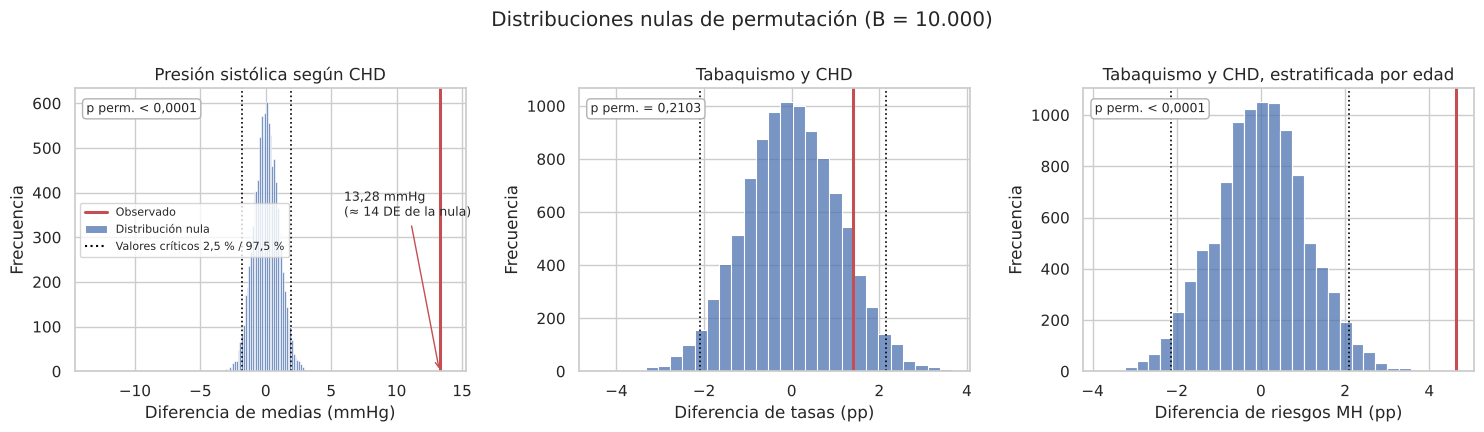

In [12]:
# La diferencia de tasas solo toma valores en una grilla de paso 1/n1 + 1/n0 (un caso de CHD que cambia de
# grupo); el ancho de barra se fija como múltiplo de ese paso para evitar un histograma "peinado".
paso_tasas = 100 * (1 / (fuma == 1).sum() + 1 / (fuma == 0).sum())
paneles = [
    (nula_dif_pas, dif_obs, "Presión sistólica según CHD", "Diferencia de medias (mmHg)", p_perm_dif_pas, None),
    (nula_dif_fuma * 100, dif_tasas_obs * 100, "Tabaquismo y CHD", "Diferencia de tasas (pp)", p_perm_fuma,
     3 * paso_tasas),
    (nula_mh * 100, dif_mh_obs * 100, "Tabaquismo y CHD, estratificada por edad",
     "Diferencia de riesgos MH (pp)", p_perm_mh, 3 * paso_tasas),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, (nula, obs, titulo, xlabel, p, ancho) in zip(axes, paneles):
    opciones = {"binwidth": ancho} if ancho else {"bins": 50}
    sns.histplot(nula, color=COLORES["principal"], alpha=.75, ax=ax, label="Distribución nula", **opciones)
    crit = np.quantile(nula, [ALPHA / 2, 1 - ALPHA / 2])
    for c in crit:
        ax.axvline(c, color="black", ls=":", lw=1.2)
    ax.axvline(obs, color=COLORES["riesgo"], lw=2.2, label="Observado")
    ax.set(title=titulo, xlabel=xlabel, ylabel="Frecuencia")
    ax.text(.03, .95, "p perm. " + (fmt_p(p) if p < 1e-4 else "= " + fmt_p(p)), transform=ax.transAxes, va="top", fontsize=9,
            bbox=dict(boxstyle="round", fc="white", ec="0.7"))
axes[0].set_xlim(min(nula_dif_pas.min(), -dif_obs) * 1.1, dif_obs * 1.15)
axes[0].annotate(f"{dif_obs:.2f} mmHg\n(≈ {z_pas:.0f} DE de la nula)".replace(".", ","), xy=(dif_obs, 0),
                 xytext=(dif_obs * .45, axes[0].get_ylim()[1] * .55),
                 arrowprops=dict(arrowstyle="->", color=COLORES["riesgo"]), fontsize=9)
handles, labels = axes[1].get_legend_handles_labels()
handles.append(plt.Line2D([], [], color="black", ls=":"))
labels.append("Valores críticos 2,5 % / 97,5 %")
axes[0].legend(handles, labels, loc="center left", fontsize=8, frameon=True)
plt.suptitle(f"Distribuciones nulas de permutación (B = {B:,})".replace(",", "."), y=1.0)
guardar_figura("p2_fig1_permutacion")

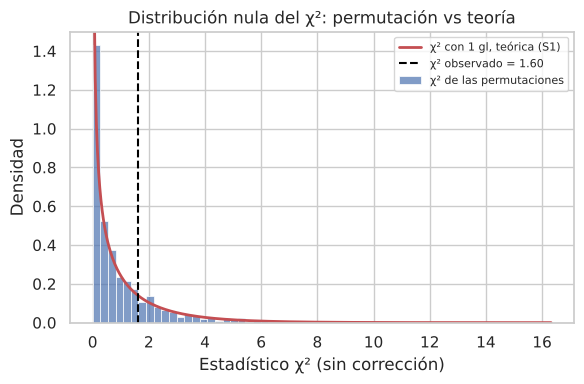

In [13]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.histplot(nula_chi2_fuma, bins=60, stat="density", color=COLORES["principal"], alpha=.7, ax=ax,
             label="χ² de las permutaciones")
xx = np.linspace(.01, nula_chi2_fuma.max(), 400)
ax.plot(xx, stats.chi2.pdf(xx, df=1), color=COLORES["riesgo"], lw=2, label="χ² con 1 gl, teórica (S1)")
ax.axvline(chi2_obs, color="black", ls="--", lw=1.5, label=f"χ² observado = {chi2_obs:.2f}")
ax.set_ylim(0, 1.5)
ax.set(xlabel="Estadístico χ² (sin corrección)", ylabel="Densidad",
       title="Distribución nula del χ²: permutación vs teoría")
ax.legend(fontsize=8)
guardar_figura("p2_fig3_chi2_nula_vs_teorica")

Tabla resumen: p paramétrico de la S1 frente al p de permutación.

In [14]:
def decision(p):
    return "Se rechaza H₀" if p < ALPHA else "No se rechaza H₀"


comparacion = pd.DataFrame([
    {"Prueba": "PAS según CHD (diferencia de medias)", "Estadístico observado": f"{dif_obs:.2f} mmHg",
     "Prueba paramétrica S1": "t de Welch", "p paramétrico": welch.pvalue,
     "p permutación": p_perm_dif_pas, "EE Monte Carlo": ee_mc(p_perm_dif_pas),
     "p SciPy": res_scipy_pas.pvalue, "Permutaciones ≥ observado": k_pas},
    {"Prueba": "PAS según CHD (t de Welch)", "Estadístico observado": f"t = {t_obs:.2f}",
     "Prueba paramétrica S1": "t de Welch", "p paramétrico": welch.pvalue,
     "p permutación": p_perm_t_pas, "EE Monte Carlo": ee_mc(p_perm_t_pas),
     "p SciPy": np.nan, "Permutaciones ≥ observado": int(np.sum(np.abs(nula_t_pas) >= abs(t_obs)))},
    {"Prueba": "Tabaquismo y CHD (diferencia de tasas)", "Estadístico observado": f"{dif_tasas_obs * 100:.2f} pp",
     "Prueba paramétrica S1": "χ² con Yates", "p paramétrico": chi_yates.pvalue,
     "p permutación": p_perm_fuma, "EE Monte Carlo": ee_mc(p_perm_fuma),
     "p SciPy": res_scipy_fuma.pvalue,
     "Permutaciones ≥ observado": int(indicador_fuma.sum())},
    {"Prueba": "Tabaquismo y CHD, estratificada por edad", "Estadístico observado": f"{dif_mh_obs * 100:.2f} pp",
     "Prueba paramétrica S1": "— (CMH como referencia)", "p paramétrico": cmh.pvalue,
     "p permutación": p_perm_mh, "EE Monte Carlo": ee_mc(p_perm_mh),
     "p SciPy": np.nan, "Permutaciones ≥ observado": int(np.sum(np.abs(nula_mh) >= abs(dif_mh_obs)))},
]).set_index("Prueba")
comparacion["Decisión paramétrica"] = comparacion["p paramétrico"].map(decision)
comparacion["Decisión permutación"] = comparacion["p permutación"].map(decision)
comparacion["¿Concuerdan?"] = np.where(
    comparacion["Decisión paramétrica"] == comparacion["Decisión permutación"], "Sí", "No")
guardar_tabla(comparacion, "p2_comparacion_p")

,Estadístico observado,Prueba paramétrica S1,p paramétrico,p permutación,EE Monte Carlo,p SciPy,Permutaciones ≥ observado,Decisión paramétrica,Decisión permutación,¿Concuerdan?
Prueba,,,,,,,,,,
PAS según CHD (diferencia de medias),13.28 mmHg,t de Welch,0.0000,0.0001,0.0001,0.0002,0,Se rechaza H₀,Se rechaza H₀,Sí
PAS según CHD (t de Welch),t = 12.01,t de Welch,0.0000,0.0001,0.0001,NaN,0,Se rechaza H₀,Se rechaza H₀,Sí
Tabaquismo y CHD (diferencia de tasas),1.40 pp,χ² con Yates,0.2211,0.2103,0.0041,0.2168,2102,No se rechaza H₀,No se rechaza H₀,Sí
"Tabaquismo y CHD, estratificada por edad",4.64 pp,— (CMH como referencia),0.0000,0.0001,0.0001,NaN,0,Se rechaza H₀,Se rechaza H₀,Sí


In [15]:
# Cifras que se citan en la discusión
print(f"PAS: p Welch = {welch.pvalue:.1e} | p permutación = {p_perm_dif_pas:.6f} (cota inferior 1/{B + 1:,})")
print(f"Tabaco: p Yates = {chi_yates.pvalue:.3f} | p sin Yates = {chi_sin.pvalue:.3f} | "
      f"p Fisher = {fisher.pvalue:.3f} | p permutación = {p_perm_fuma:.3f} ± {ee_mc(p_perm_fuma):.3f}")
print(f"Tabaco ajustado por edad: dif MH = {dif_mh_obs * 100:.2f} pp | p permutación = {p_perm_mh:.4f} "
      f"| p CMH = {cmh.pvalue:.4f}")
print(f"Media y DE de la nula del χ² permutado: {nula_chi2_fuma.mean():.3f} / {nula_chi2_fuma.std(ddof=1):.3f} "
      f"(teóricas χ²₁: 1 / {np.sqrt(2):.3f})")

PAS: p Welch = 1.2e-30 | p permutación = 0.000100 (cota inferior 1/10,001)
Tabaco: p Yates = 0.221 | p sin Yates = 0.205 | p Fisher = 0.215 | p permutación = 0.210 ± 0.004
Tabaco ajustado por edad: dif MH = 4.64 pp | p permutación = 0.0001 | p CMH = 0.0000
Media y DE de la nula del χ² permutado: 0.982 / 1.369 (teóricas χ²₁: 1 / 1.414)


## 2.5 Discusión

**Prueba 1 (presión sistólica y CHD): concordancia total.** Ninguna de las 10.000 permutaciones produjo una
diferencia tan extrema como la observada: la mayor diferencia bajo H₀ fue de 3,43 mmHg, frente a 13,28 mmHg
observados, que quedan a unas 14 desviaciones estándar del centro de la distribución nula. El p de
permutación queda en su cota inferior, 1/10.001 ≈ 0,0001. No es el p "exacto", sino el menor valor que se
puede resolver con B = 10.000. Es consistente con el p de Welch de la S1 (≈ 1,2 × 10⁻³⁰). El mismo resultado se
obtiene con el t de Welch como estadístico y con `scipy.stats.permutation_test` (la DE de la nula fue 0,952 en
la implementación manual y 0,948 en SciPy). La conclusión de la S1 se valida sin depender de la normalidad,
que la S1 había rechazado con la prueba de D'Agostino-Pearson. En este caso ambos enfoques son adecuados. Con 644 y 3.596
observaciones el Teorema Central del Límite hace que el t de Welch sea confiable pese a la asimetría, y la
permutación lo confirma sin supuestos distribucionales. El t de Welch tiene además la ventaja de entregar
un IC para la diferencia y de distinguir p muy pequeños, que la permutación no puede resolver.

**Prueba 2 (tabaquismo y CHD): concordancia en la decisión.** El p de permutación (0,210 ± 0,004 de error
Monte Carlo) está muy cerca del χ² sin corrección (0,205) y del test exacto de Fisher (0,215). Es algo menor que
el p con corrección de Yates usado en la S1 (0,221), lo que coincide con que Yates es conservador. Los cuatro
enfoques llevan a la misma decisión: no se rechaza H₀. La convergencia muestra que el p de permutación se
estabiliza desde unas 2.500 permutaciones, con un coeficiente de variación de 1,9 % al llegar a 10.000. La
distribución nula del χ² obtenida por permutación (media 0,98; DE 1,37) se parece mucho a la χ² con 1 gl
teórica (media 1; DE 1,41). Por eso, con frecuencias esperadas mínimas superiores a 300, la aproximación
asintótica de la S1 era válida. Aquí la permutación resulta más apropiada como prueba de referencia, porque
es exacta condicional a los márgenes y no depende de la aproximación χ² ni de la corrección de continuidad.
Aun así, en este caso la diferencia práctica entre ambos enfoques es nula.

**Lo que agrega la permutación estratificada.** La conclusión que no es robusta es la de "no asociación", y no
por el método de inferencia, sino por la confusión. Al permutar solo dentro de los tramos de edad, la
diferencia de riesgos ajustada sube de 1,40 pp a 4,64 pp, y ninguna permutación estratificada la alcanza
(p ≤ 0,0001, en concordancia con la prueba CMH, p < 0,0001; OR de Mantel-Haenszel = 1,47). Esto confirma con
un método no paramétrico la hipótesis de la S1: la edad enmascara el efecto del tabaquismo. Los IC bootstrap
por tramo muestran que la diferencia es positiva en los tramos ≤ 45 años (4,2 pp, IC BCa [1,8; 6,5]) y 46–55
años (5,5 pp, [1,8; 9,2]), mientras que en el tramo > 55 años (4,0 pp, [−1,2; 9,4]) el IC incluye cero. Esto se
explica porque ese tramo es el que tiene menos fumadores (416) y la mayor tasa basal de CHD.

**Síntesis y elección del método.** Las dos pruebas de la S1 se validan: las decisiones paramétricas y de
permutación coinciden en todos los casos. Para este caso de estudio, el enfoque de permutación es el más
apropiado como verificación, porque no exige normalidad ni aproximaciones asintóticas. Su versión
estratificada es la única de las pruebas aplicadas que responde a la pregunta relevante para el riesgo
coronario (¿fumar se asocia a CHD *a igual edad*?). Las limitaciones son la resolución del p (1/10.001), el
error Monte Carlo que hay que informar y el supuesto de intercambiabilidad bajo H₀, que también exige
observaciones independientes. En la siguiente fase, el efecto del tabaquismo debe estimarse ajustado por edad (por
ejemplo, con regresión logística múltiple) y no a partir de la asociación marginal.